# Lab 7 (Part A): PCA and SVD for Dimensionality Reduction
**IC-709D | AI Lab**

**Aim:** Understand dimensionality reduction with Principal Component Analysis (PCA) and Singular Value
Decomposition (SVD): implement PCA from scratch using SVD, verify it against scikit-learn, study explained
variance, projection and reconstruction, and compare PCA with other feature extraction techniques.

**Dataset:** scikit-learn `digits` (1797 images of handwritten digits, 8 x 8 pixels = 64 features, 10 classes).
It ships with scikit-learn, so no download is needed.

| Section | Topic |
|---|---|
| 1 | Load and view the data |
| 2 | PCA from scratch using SVD (and verification) |
| 3 | Explained variance and choosing the number of components |
| 4 | 2-D projection |
| 5 | Reconstruction and reconstruction error |
| 6 | Effect of the number of components on classification |
| 7 | Analysis: PCA vs other feature extraction techniques |
| 8 | Conclusion and learning outcomes |

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.decomposition import PCA, KernelPCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.random_projection import GaussianRandomProjection

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)   # figures are saved here
RANDOM_STATE = 42
print("Libraries loaded.")

Libraries loaded.


## 1. Load and view the data

Samples: 1797 | Features: 64 | Classes: 10
Pixel value range: 0.0 to 16.0


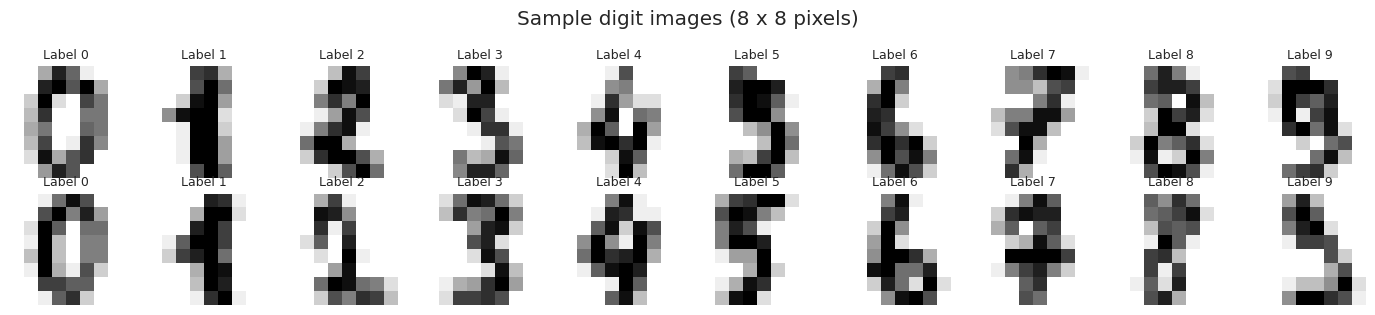

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Samples:", X.shape[0], "| Features:", X.shape[1], "| Classes:", len(np.unique(y)))
print("Pixel value range:", X.min(), "to", X.max())

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[index], cmap="gray_r")
    ax.set_title(f"Label {y[index]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Sample digit images (8 x 8 pixels)")
plt.tight_layout()
plt.savefig("outputs/pca_sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. PCA from scratch using SVD
**Idea:** PCA finds new axes (principal components) along which the data varies the most.

1. Centre the data: subtract the mean of every feature, giving `Xc`.
2. Apply SVD: `Xc = U S Vt`.
3. The rows of `Vt` are the principal directions. The variance along each is `S^2 / (n - 1)`.
4. Project onto the first `k` directions: `Z = Xc @ Vt[:k].T`.

SVD and the eigen-decomposition of the covariance matrix give the same answer, which is checked below.

In [3]:
def pca_via_svd(data):
    """Return the mean, singular values and principal directions of `data`."""
    mean_vector = data.mean(axis=0)
    centered = data - mean_vector
    _, singular_values, directions = np.linalg.svd(centered, full_matrices=False)
    return mean_vector, singular_values, directions


mean_vector, S, Vt = pca_via_svd(X)
X_centered = X - mean_vector
n_samples = X.shape[0]

eigenvalues = (S ** 2) / (n_samples - 1)          # variance along each component
explained_ratio = eigenvalues / eigenvalues.sum()  # fraction of total variance

# Check 1: eigen-decomposition of the covariance matrix gives the same variances
cov_eigenvalues = np.sort(np.linalg.eigvalsh(np.cov(X_centered.T)))[::-1]
print("SVD variances == covariance eigenvalues:", np.allclose(eigenvalues, cov_eigenvalues, atol=1e-8))

# Check 2: scikit-learn PCA gives the same variance ratios and directions (up to sign)
sk_pca = PCA(n_components=None, svd_solver="full").fit(X)
print("Variance ratios match scikit-learn      :", np.allclose(explained_ratio, sk_pca.explained_variance_ratio_))
print("First 20 directions match (up to sign)  :", np.allclose(np.abs(Vt[:20]), np.abs(sk_pca.components_[:20]), atol=1e-6))

SVD variances == covariance eigenvalues: True
Variance ratios match scikit-learn      : True
First 20 directions match (up to sign)  : True


## 3. Explained variance and choosing the number of components

Components needed for 90% variance: 21
Components needed for 95% variance: 29
Components needed for 99% variance: 41
Variance explained by the first 2 components: 28.5%


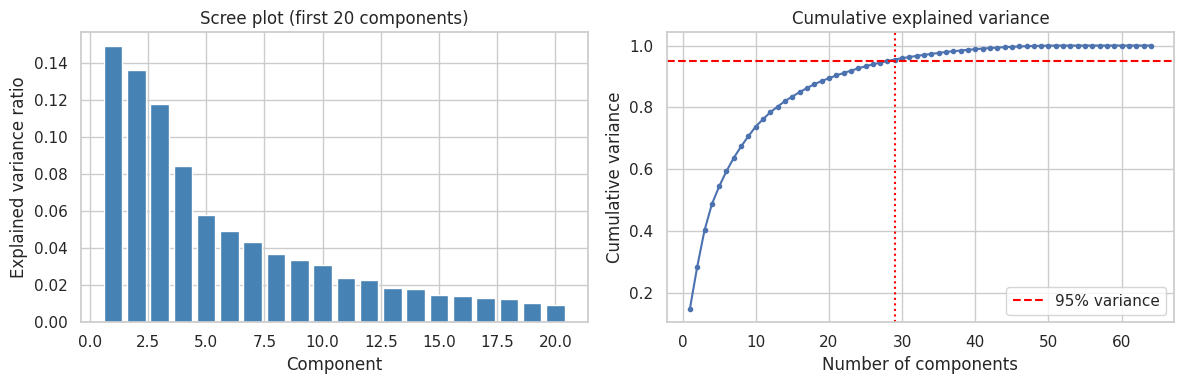

In [4]:
cumulative = np.cumsum(explained_ratio)
k_90 = int(np.searchsorted(cumulative, 0.90) + 1)
k_95 = int(np.searchsorted(cumulative, 0.95) + 1)
k_99 = int(np.searchsorted(cumulative, 0.99) + 1)
print(f"Components needed for 90% variance: {k_90}")
print(f"Components needed for 95% variance: {k_95}")
print(f"Components needed for 99% variance: {k_99}")
print(f"Variance explained by the first 2 components: {cumulative[1] * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, 21), explained_ratio[:20], color="steelblue")
axes[0].set_title("Scree plot (first 20 components)")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Explained variance ratio")

axes[1].plot(range(1, len(cumulative) + 1), cumulative, marker="o", markersize=3)
axes[1].axhline(0.95, color="red", linestyle="--", label="95% variance")
axes[1].axvline(k_95, color="red", linestyle=":")
axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance")
axes[1].legend()
plt.tight_layout()
plt.savefig("outputs/pca_explained_variance.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** the first 2 components explain only 28.5% of the variance, but 29 components (less than half of the 64 original features) are enough for 95% and 41 for 99%. The scree plot drops quickly after the first few components, which means many pixels are correlated and the data can be compressed a lot. A common rule is to keep enough components for 90 to 95% of the variance (here 21 to 29 components).

## 4. Projection to 2-D

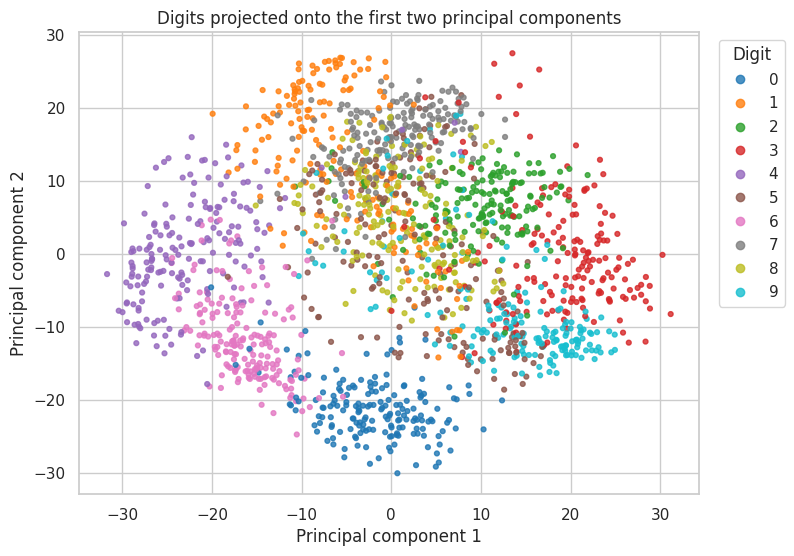

In [5]:
Z2 = X_centered @ Vt[:2].T     # project every image onto the first two components

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z2[:, 0], Z2[:, 1], c=y, cmap="tab10", s=12, alpha=0.8)
plt.legend(*scatter.legend_elements(), title="Digit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Digits projected onto the first two principal components")
plt.savefig("outputs/pca_2d_projection.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** even with two components (28.5% of the variance) some digits form clear groups: 0 (bottom), 4 and 6 (left) and 3 (right) are fairly well separated. Digits such as 5, 7, 8 and 9 overlap heavily in the middle, so two components are not enough to separate all ten classes. PCA does not use the labels; the colours are added only for viewing.

## 5. Reconstruction and reconstruction error
Using only `k` components, an image can be rebuilt as `Xc @ Vt[:k].T @ Vt[:k] + mean`.
The mean squared error (MSE) between the original and the rebuilt image measures the information lost.

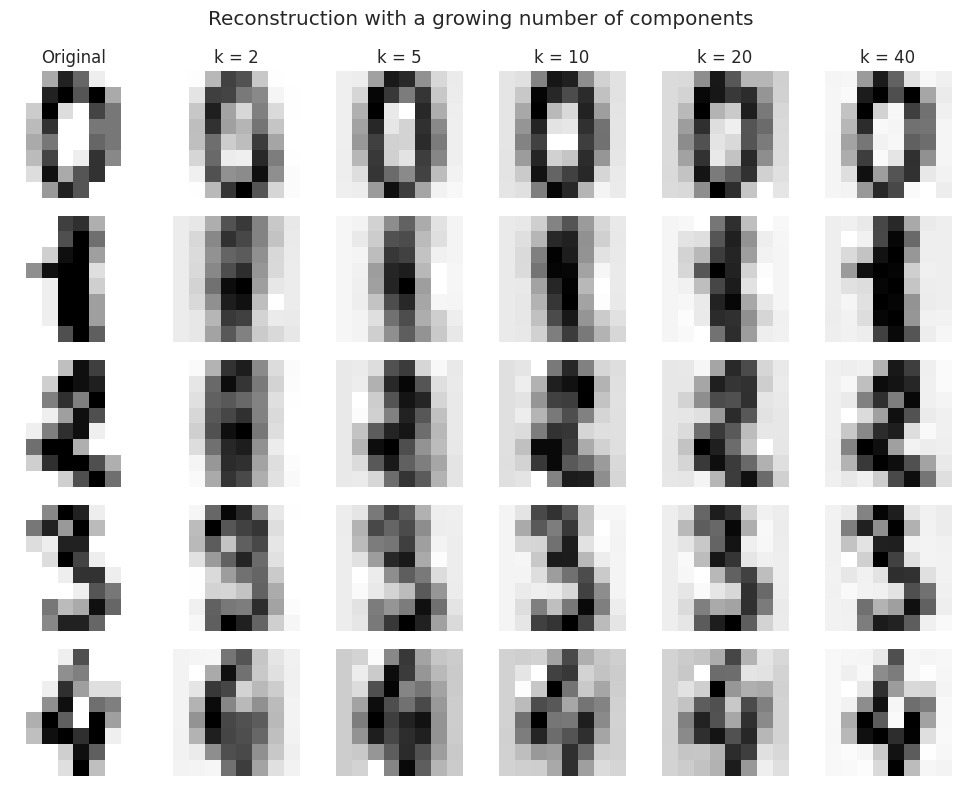

In [6]:
def reconstruct(data_centered, directions, k, mean):
    """Project onto the first k directions and map back to pixel space."""
    return data_centered @ directions[:k].T @ directions[:k] + mean


k_values = [2, 5, 10, 20, 40]
show_indices = [0, 1, 2, 3, 4]

fig, axes = plt.subplots(len(show_indices), len(k_values) + 1, figsize=(10, 8))
for row, index in enumerate(show_indices):
    axes[row, 0].imshow(X[index].reshape(8, 8), cmap="gray_r")
    axes[row, 0].set_title("Original" if row == 0 else "")
    for col, k in enumerate(k_values, start=1):
        rebuilt = reconstruct(X_centered[index:index + 1], Vt, k, mean_vector)
        axes[row, col].imshow(rebuilt.reshape(8, 8), cmap="gray_r")
        if row == 0:
            axes[row, col].set_title(f"k = {k}")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Reconstruction with a growing number of components")
plt.tight_layout()
plt.savefig("outputs/pca_reconstruction.png", dpi=150, bbox_inches="tight")
plt.show()

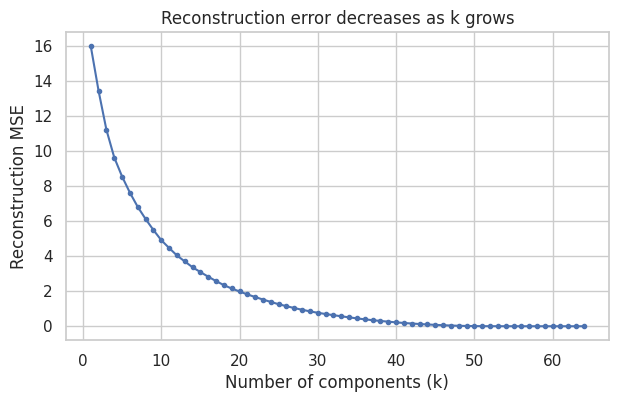

k =  2: MSE = 13.4210
k = 10: MSE = 4.9143
k = 20: MSE = 1.9843
k = 40: MSE = 0.2215
k = 64: MSE = 0.0000


In [7]:
all_k = list(range(1, 65))
mse_values = [np.mean((X - reconstruct(X_centered, Vt, k, mean_vector)) ** 2) for k in all_k]

plt.figure(figsize=(7, 4))
plt.plot(all_k, mse_values, marker="o", markersize=3)
plt.xlabel("Number of components (k)")
plt.ylabel("Reconstruction MSE")
plt.title("Reconstruction error decreases as k grows")
plt.savefig("outputs/pca_reconstruction_error.png", dpi=150, bbox_inches="tight")
plt.show()

for k in [2, 10, 20, 40, 64]:
    print(f"k = {k:>2}: MSE = {mse_values[k - 1]:.4f}")

**Observation:** with k = 2 only a rough blob of the digit is visible, by k = 10 to 20 the main shape of most digits can be seen, and at k = 40 the images are very close to the originals. The MSE falls steadily from 13.42 (k = 2) to 4.91 (k = 10), 1.98 (k = 20), 0.22 (k = 40) and exactly 0 at k = 64, because using all components keeps all the information.

## 6. Effect of the number of components on classification
A Logistic Regression classifier is trained on the first `k` principal components and tested on held-out data.
PCA is fitted on the training set only (inside the pipeline), so the test set stays unseen.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

rows = []
for k in [2, 5, 10, 20, 30, 40, 64]:
    pipeline = Pipeline([("pca", PCA(n_components=k, random_state=RANDOM_STATE)),
                         ("clf", LogisticRegression(max_iter=3000))])
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_time = time.perf_counter() - start
    rows.append({"Components": k, "Test accuracy": round(pipeline.score(X_test, y_test), 4),
                 "Fit time (s)": round(fit_time, 4)})

baseline = LogisticRegression(max_iter=3000)
start = time.perf_counter()
baseline.fit(X_train, y_train)
baseline_time = time.perf_counter() - start
baseline_accuracy = baseline.score(X_test, y_test)

accuracy_vs_k = pd.DataFrame(rows)
print(f"Baseline (all 64 raw pixels, no PCA): accuracy = {baseline_accuracy:.4f}, fit time = {baseline_time:.4f} s")
accuracy_vs_k

Baseline (all 64 raw pixels, no PCA): accuracy = 0.9622, fit time = 0.0761 s


,Components,Test accuracy,Fit time (s)
0,2,0.5911,0.0964
1,5,0.8378,0.2478
2,10,0.9156,0.2454
3,20,0.9289,0.0780
4,30,0.9578,0.0485
5,40,0.9578,0.0635
6,64,0.9622,0.0607


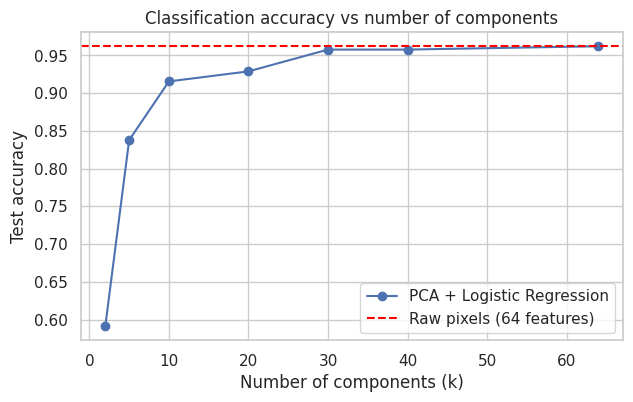

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(accuracy_vs_k["Components"], accuracy_vs_k["Test accuracy"], marker="o", label="PCA + Logistic Regression")
plt.axhline(baseline_accuracy, color="red", linestyle="--", label="Raw pixels (64 features)")
plt.xlabel("Number of components (k)")
plt.ylabel("Test accuracy")
plt.title("Classification accuracy vs number of components")
plt.legend()
plt.savefig("outputs/pca_accuracy_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** accuracy rises quickly with k: 59.1% with 2 components, 91.6% with 10 and 95.8% with 30, while the raw 64 pixels give 96.2%. So 30 components keep almost all the useful information (53% fewer features) at a cost of less than half a percentage point.

Fit time is not clearly smaller with PCA here: all values are a fraction of a second and noisy because the dataset is tiny. The speed benefit of fewer features shows up on much larger data.

## 7. Analysis: PCA compared with other feature extraction techniques
Every technique reduces the 64 pixels to a small number of new features, and a Logistic Regression
classifier is evaluated with 5-fold cross-validation (the extractor is fitted inside each training fold).

| Technique | Idea | Uses labels? |
|---|---|---|
| PCA | Directions of maximum variance (data is centred) | No |
| Truncated SVD | Like PCA but without centring | No |
| Gaussian Random Projection | Multiplies by a random matrix; keeps distances approximately | No |
| LDA | Directions that best separate the classes (at most classes - 1 = 9) | Yes |
| Kernel PCA (RBF) | PCA in a non-linear feature space | No |

In [10]:
N_COMPONENTS = 20

extractors = {
    "Raw pixels (no extraction)": (None, "-", 64),
    "PCA": (PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE), "Unsupervised, linear", N_COMPONENTS),
    "Truncated SVD": (TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE), "Unsupervised, linear", N_COMPONENTS),
    "Random Projection": (GaussianRandomProjection(n_components=N_COMPONENTS, random_state=RANDOM_STATE), "Unsupervised, random", N_COMPONENTS),
    "LDA": (LinearDiscriminantAnalysis(n_components=9), "Supervised, linear", 9),
    "Kernel PCA (RBF)": (KernelPCA(n_components=N_COMPONENTS, kernel="rbf", gamma=0.001, random_state=RANDOM_STATE), "Unsupervised, non-linear", N_COMPONENTS),
}

splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, (extractor, kind, dims) in extractors.items():
    steps = [("clf", LogisticRegression(max_iter=3000))]
    if extractor is not None:
        steps.insert(0, ("extract", extractor))
    scores = cross_val_score(Pipeline(steps), X, y, cv=splitter, scoring="accuracy")

    # time needed to fit the extractor once on the full data
    if extractor is None:
        fit_time = 0.0
    else:
        start = time.perf_counter()
        if name == "LDA":
            extractor.fit(X, y)
        else:
            extractor.fit(X)
        fit_time = time.perf_counter() - start

    rows.append({"Technique": name, "Type": kind, "Features": dims,
                 "CV accuracy": round(scores.mean(), 4), "Std": round(scores.std(), 4),
                 "Fit time (s)": round(fit_time, 4)})

technique_comparison = pd.DataFrame(rows)
technique_comparison

,Technique,Type,Features,CV accuracy,Std,Fit time (s)
0,Raw pixels (no extraction),-,64,0.9666,0.0046,0.0000
1,PCA,"Unsupervised, linear",20,0.9488,0.0125,0.0016
2,Truncated SVD,"Unsupervised, linear",20,0.9471,0.0076,0.0113
3,Random Projection,"Unsupervised, random",20,0.8959,0.0083,0.0010
4,LDA,"Supervised, linear",9,0.9521,0.0065,0.0077
5,Kernel PCA (RBF),"Unsupervised, non-linear",20,0.9393,0.0064,0.5576


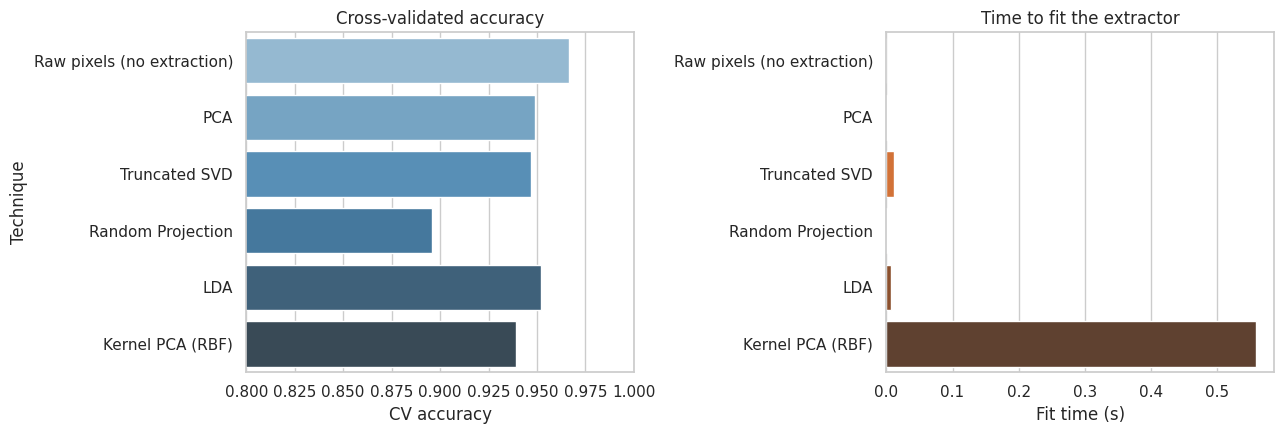

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=technique_comparison, y="Technique", x="CV accuracy", ax=axes[0], palette="Blues_d")
axes[0].set_xlim(0.8, 1.0)
axes[0].set_title("Cross-validated accuracy")
sns.barplot(data=technique_comparison, y="Technique", x="Fit time (s)", ax=axes[1], palette="Oranges_d")
axes[1].set_title("Time to fit the extractor")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("outputs/pca_technique_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation**
- The raw pixels give the best cross-validated accuracy (0.967), followed by LDA (0.952 with only 9 features), PCA (0.949) and Truncated SVD (0.947) with 20 features each.
- Kernel PCA (0.939) is by far the slowest (0.62 s against about 0.002 s for PCA) and does not help on this dataset.
- Random Projection is the weakest (0.896): it preserves distances only approximately and does not look for the directions that matter.
- LDA gets close to PCA with fewer than half the features because it uses the labels, but it can produce at most (classes - 1) = 9 features.
- Truncated SVD performs almost the same as PCA here.

**Take-away:** on this small, clean dataset no extractor beats the raw pixels. Dimensionality reduction is still useful for visualisation, noise removal, smaller models and faster training on large data. Differences of one or two hundredths are close to the standard deviation across folds (about 0.005 to 0.013), so only the larger gaps (Random Projection, raw pixels vs PCA) are reliable.

## 8. Conclusion and learning outcomes
- Implemented PCA from scratch with SVD and verified it against the covariance eigen-decomposition and scikit-learn.
- Used the scree plot and cumulative variance to choose the number of components.
- Visualised high-dimensional data in 2-D and saw how much information is kept or lost.
- Measured reconstruction error and the effect of `k` on classification accuracy and training time.
- Compared PCA with Truncated SVD, Random Projection, LDA and Kernel PCA and learned when each one is suitable.